# 03. Archives, ML-ready packaging, simulations and surrogates

**Goal.** Measure how much of each raw geoscience archive, and of solid-earth simulation output, exists in ML-ready form, and how often simulation communities use ML surrogates.

**Inputs.** All in `docs/archive_readiness_2026-10-30/`:

| File | Content | Method |
|---|---|---|
| `archives.json` | 16 raw-archive volumes | web research of agency pages, reports, papers |
| `benchmarks.json` | 30 ML-ready observational benchmarks | dataset pages, papers, Zenodo/Hugging Face API metadata |
| `simulation_corpora.json` | 16 simulation archives and ML-ready simulation corpora | project pages, papers, repository APIs |
| `simulation_counts.json` | simulation and ML-surrogate articles by field, subfield, year | `scripts/platform_readiness_counts.py`, OpenAlex, keyless |

Web-researched volumes cannot be re-queried by a script: each row carries its source URL, as-of date, and a flag saying whether the quote was read in the source text. The OpenAlex counts can be re-queried (`scripts/requery_check.py`; see notebook 02).

**Pairing rule.** A benchmark is compared only with the archive it was drawn from. A benchmark is a designed subsample, so a small share is not by itself a deficit; it bounds what can be trained without new curation.

In [1]:
import json, csv, hashlib, os, subprocess, sys
from collections import Counter, defaultdict
from pathlib import Path
from IPython.display import Image, Markdown, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pixi.toml").exists())
sys.path.insert(0, str(ROOT / "tools"))
def table(header, rows):
    """Render rows as a Markdown table."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))
print("repository root:", ROOT)

repository root: /Users/marinedenolle/GitHub/geoscience-ai-readiness


In [2]:
DOCS = ROOT / "docs/archive_readiness_2026-10-30"
archives = json.loads((DOCS / "archives.json").read_text())["archives"]
human = lambda b: "not published" if b is None else next(f"{b/s:.3g} {u}" for u, s in (("PB", 1e15), ("TB", 1e12), ("GB", 1e9), ("MB", 1e6), ("B", 1)) if b >= s)
table(["Archive", "Volume", "As of", "Projection", "Quote checked in source", "Weakness"],
      [[a["archive"], a["stated"], a["as_of"], a["projection"], a["checked_in_text"], a.get("weak", "")] for a in archives])

| Archive | Volume | As of | Projection | Quote checked in source | Weakness |
|---|---|---|---|---|---|
| NASA EOSDIS (Earthdata), incl. cloud copies | 225.7 PB | Oct 2025-Sep 2026 | False | True |  |
| NASA Earth Science, deduplicated | 127,665 TB | FY2024 | False | True |  |
| ASF DAAC SAR archive | >20 PB | 2023-05 | False | False | secondary source (talk announcement) |
| NISAR expected volume | ~40 PB per year | 2025-07 | True | False |  |
| EarthScope seismic archive | >1 PB | 2025 | False | False |  |
| EarthScope geodetic archive (GAGE) | >300 TB | Feb 2020 | False | True | pre-2023 |
| USGS Landsat archive | >13.8 PB (USGS 2023 slide: 20 PB) | 2025-09 | False | False |  |
| Copernicus Data Space Ecosystem (Sentinel) | ~91 PB online | end 2025 | False | False |  |
| NSF NCAR GDEX (former RDA) | 9 PB migrated | 2025-09 | False | False | volume migrated, not stated as total |
| NOAA NCEI | >60 PB | late 2023 | False | False |  |
| ECMWF MARS | 718 PB (2022 page: 510 PB primary + 188 PB secondary) | 2025-10 | False | True | garbled slide; backups not stated |
| ECMWF ERA5 (raw, on MARS) | about 10 PB | 2026-09 | False | False |  |
| CMIP6 on ESGF, distinct | >16 PB distinct (28 PB with replicas) | 2025-11 | False | False |  |
| OOI raw data | 2.8 PB | 2025-01 | False | False |  |
| USGS NWIS / Water Data for the Nation | not found (>1.5 million sites) | None | False | False |  |
| DAS raw data (no central archive) | not found | None | False | False |  |

## 1. Raw archive against ML-ready packaging, by discipline

In [3]:
import importlib.util
spec = importlib.util.spec_from_file_location("arf", ROOT / "scripts/archive_readiness_figures.py")
arf = importlib.util.module_from_spec(spec); spec.loader.exec_module(arf)
rows = arf.pairs_table()
table(["Discipline", "Archive", "ML-ready packaged", "Share", "Caveat"],
      [[r["row"], human(r["archive_bytes"]), human(r["packaged_bytes"]),
        "" if r["share_percent"] is None else (f'{r["share_percent"]:.2g}%' if r["share_percent"] >= 0.001 else "below 0.001%"), r["caveat"]] for r in rows])

| Discipline | Archive | ML-ready packaged | Share | Caveat |
|---|---|---|---|---|
| Reanalysis: ERA5 | 10 PB | 2.05 PB | 20% | ARCO-ERA5 pressure and surface levels only; the model-level store adds 5.88 PB |
| Seismology | 1 PB | 2.66 TB | 0.27% | benchmarks also draw on SCEDC, NCEDC, INGV and Swiss archives; EarthScope alone is the denominator, so the share is an upper bound |
| SAR: Sentinel-1 | 20 PB | 16 TB | 0.08% | ASF figure from 2023, secondary source; ASF also holds non-Sentinel SAR |
| Optical: Sentinel-2 | 91 PB | 25.1 TB | 0.028% | CDSE volume covers all Sentinel missions; Major TOM L1C (another ~23 TB) not added |
| Climate projections: CMIP6 | 16 PB | 2.39 GB | below 0.001% | ClimateBench uses one model, NorESM2 |
| Geodesy: GNSS | 300 TB | not published |  | archive figure from 2020; no released ML-ready GNSS benchmark found |
| Ocean observatory: OOI | 2.8 PB | not published |  | no ML-ready benchmark derived from OOI found |
| DAS | not published | 680 GB |  | DAS has no central archive with a published volume |
| Hydrology: gauges | not published | 54.2 GB |  | USGS NWIS publishes site counts, not bytes |

## 2. ML surrogates per 100 simulation articles

An index from keyword co-occurrence (OpenAlex, 2023 to 2025): articles naming an ML surrogate per 100 articles naming a numerical method. It is not the share of simulation papers that use surrogates.

In [4]:
sim = json.loads((DOCS / "simulation_counts.json").read_text())["simulation"]
f_sim, f_sur = sim["field_sim_2023_2025"], sim["field_surr_ml_2023_2025"]
rows = sorted(((v["name"], f_sur.get(k, {}).get("count", 0), v["count"]) for k, v in f_sim.items() if v["count"] >= 2000), key=lambda r: -r[1] / r[2])
table(["Field", "ML-surrogate articles", "Simulation articles", "Index"], [[n, f"{m:,}", f"{s:,}", f"{100*m/s:.1f}"] for n, m, s in rows])
s_sim, s_sur = sim["subfield_sim_2023_2025"], sim["subfield_surr_ml_2023_2025"]
rows = sorted(((v["name"], s_sur.get(k, {}).get("count", 0), v["count"]) for k, v in s_sim.items() if v["count"] >= 500), key=lambda r: -r[1] / r[2])
table(["Earth or environmental subfield", "ML-surrogate articles", "Simulation articles", "Index"], [[n, m, f"{s:,}", f"{100*m/s:.1f}"] for n, m, s in rows])

| Field | ML-surrogate articles | Simulation articles | Index |
|---|---|---|---|
| Physics and Astronomy | 4,033 | 12,611 | 32.0 |
| Computer Science | 1,280 | 7,735 | 16.5 |
| Environmental Science | 448 | 5,114 | 8.8 |
| Earth and Planetary Sciences | 293 | 4,574 | 6.4 |
| Materials Science | 389 | 10,219 | 3.8 |
| Engineering | 4,143 | 147,345 | 2.8 |
| Medicine | 228 | 11,284 | 2.0 |
| Mathematics | 111 | 5,994 | 1.9 |

| Earth or environmental subfield | ML-surrogate articles | Simulation articles | Index |
|---|---|---|---|
| Global and Planetary Change | 104 | 642 | 16.2 |
| Atmospheric Science | 125 | 924 | 13.5 |
| Environmental Engineering | 243 | 2,176 | 11.2 |
| Oceanography | 62 | 871 | 7.1 |
| Geophysics | 88 | 1,665 | 5.3 |
| Earth-Surface Processes | 15 | 801 | 1.9 |
| Management, Monitoring, Policy and Law | 11 | 732 | 1.5 |

## 3. Solid-earth simulation output against ML-ready simulation corpora

In [5]:
sc = json.loads((DOCS / "simulation_corpora.json").read_text())["rows"]
ml = [r for r in sc if r["side"] == "ML-ready simulation corpus"]
tot = lambda rs: sum(r["bytes"] for r in rs)
table(["Group", "Total", "Items"], [
    ["Solid earth, ML-ready corpora", human(tot([r for r in ml if r["domain"] == "solid_earth"])), ", ".join(r["name"] for r in ml if r["domain"] == "solid_earth")],
    ["Other physics and atmosphere, ML-ready corpora", human(tot([r for r in ml if r["domain"] != "solid_earth"])), ", ".join(r["name"] for r in ml if r["domain"] != "solid_earth")],
    ["CyberShake 22.12, output kept", human(next(r["bytes"] for r in sc if r["name"].startswith("CyberShake Study 22.12, archived"))), "one study"],
    ["CyberShake 22.12, handled during the run", human(next(r["bytes"] for r in sc if r["name"].startswith("CyberShake Study 22.12, managed"))), "one study"]])
print("Rows whose total is summed from repository file sizes:", [r["name"] for r in sc if r["computed"]])

| Group | Total | Items |
|---|---|---|
| Solid earth, ML-ready corpora | 2.48 TB | OpenFWI, HEMEW-3D, EQGNS rupture GNN, RuptureNet2D |
| Other physics and atmosphere, ML-ready corpora | 101 TB | DrivAerNet++, The Well, PDEBench, BLASTNet 2.0, WaveBench, AirfRANS, ClimSim high-res |
| CyberShake 22.12, output kept | 75 TB | one study |
| CyberShake 22.12, handled during the run | 2.5 PB | one study |

Rows whose total is summed from repository file sizes: ['EQGNS rupture GNN', 'RuptureNet2D', 'PDEBench', 'WaveBench', 'AirfRANS']


## 4. Figures

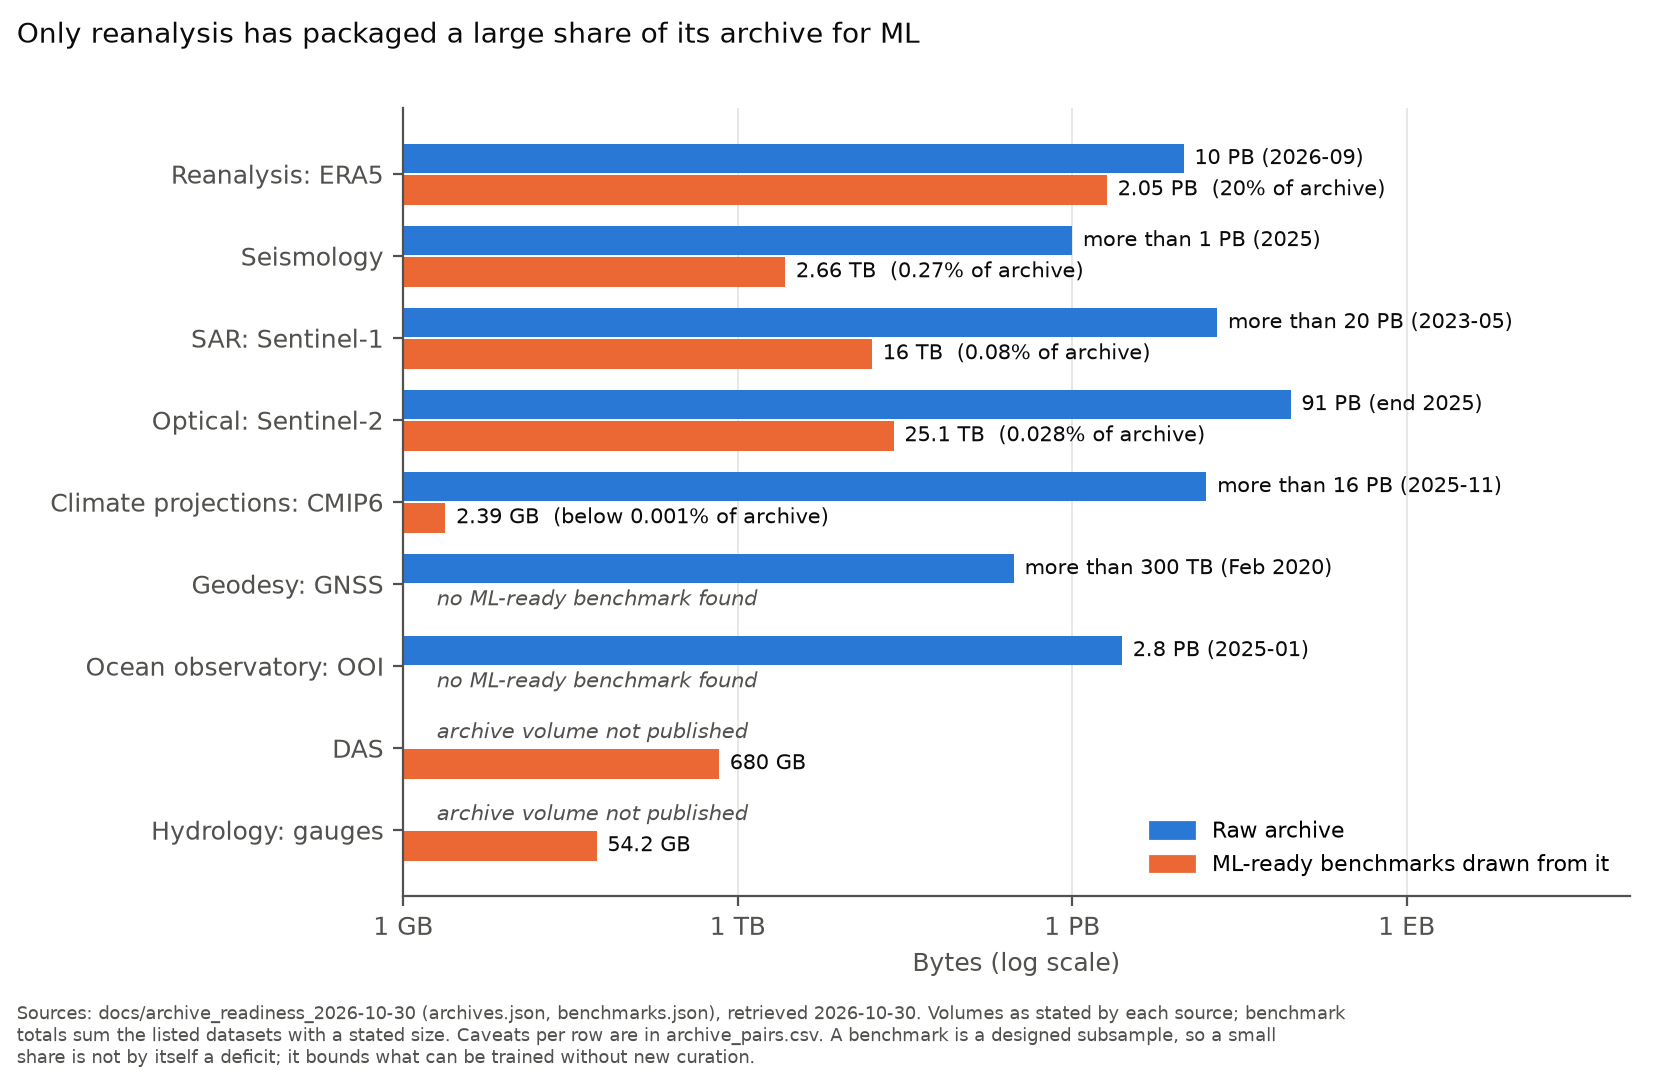

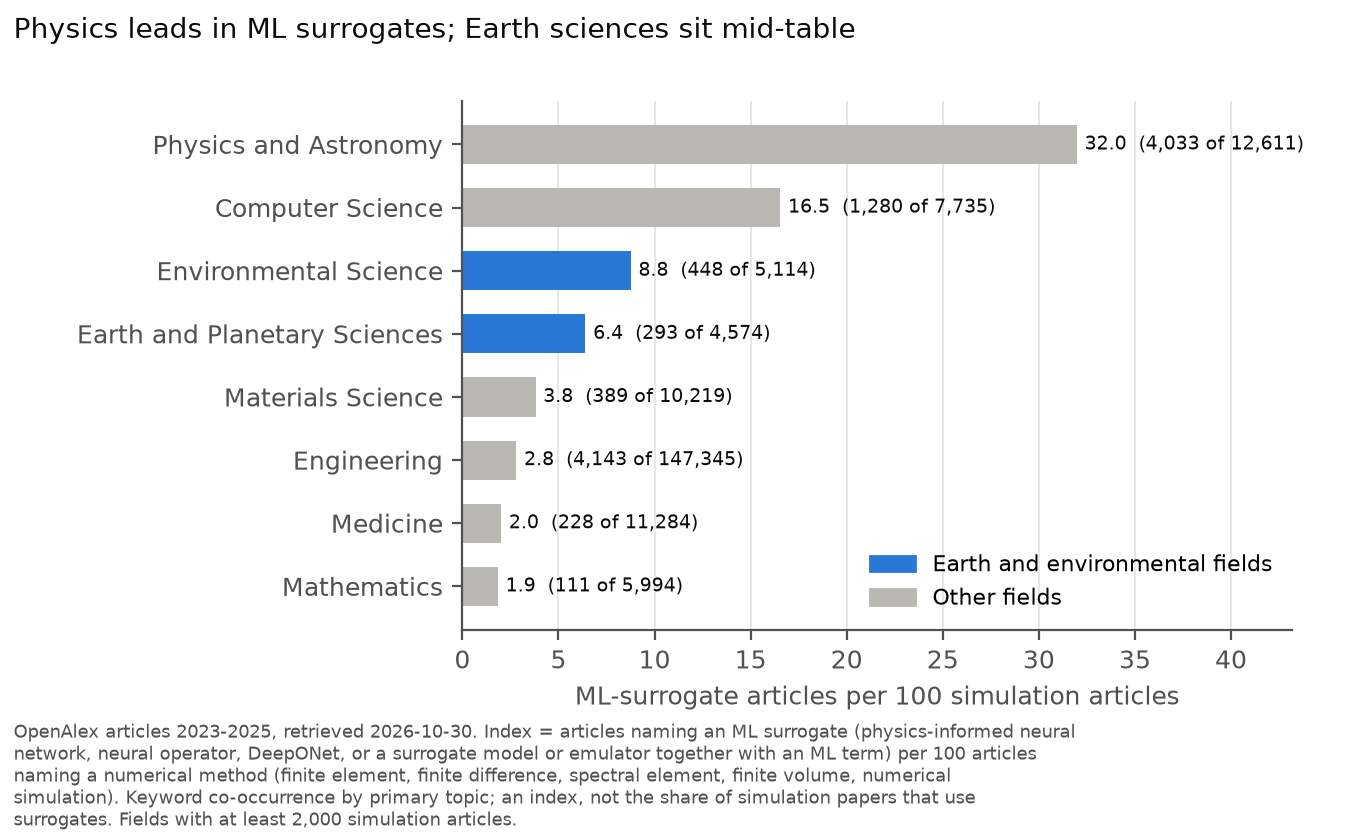

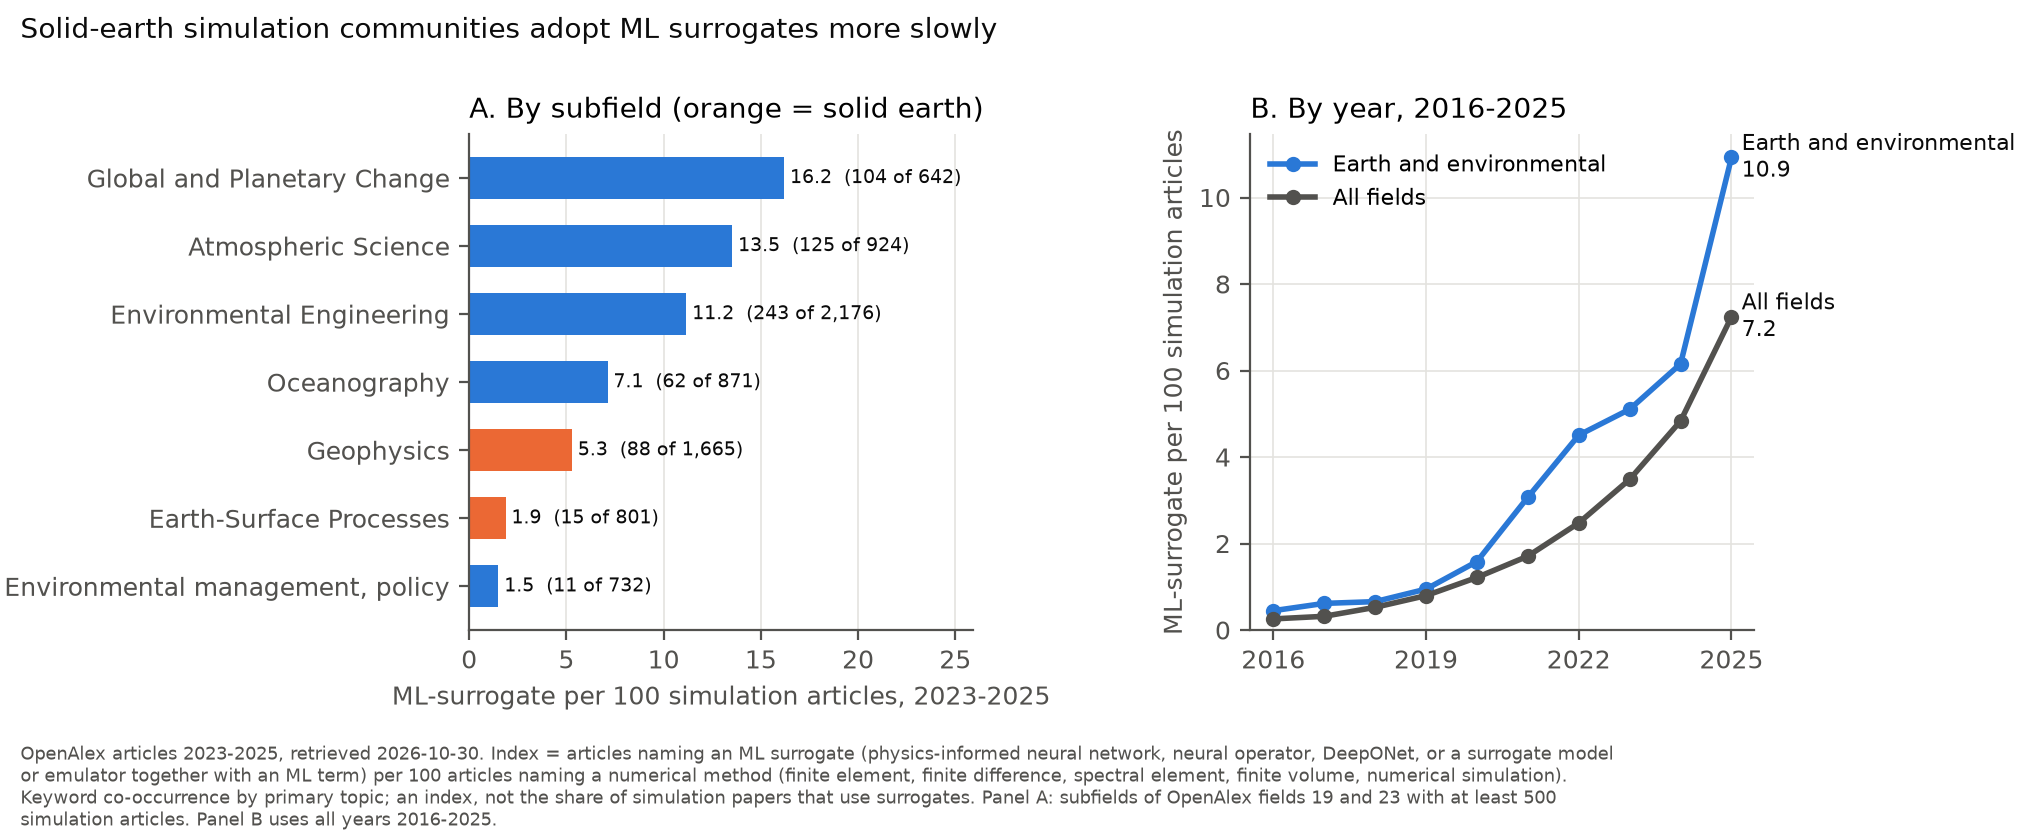

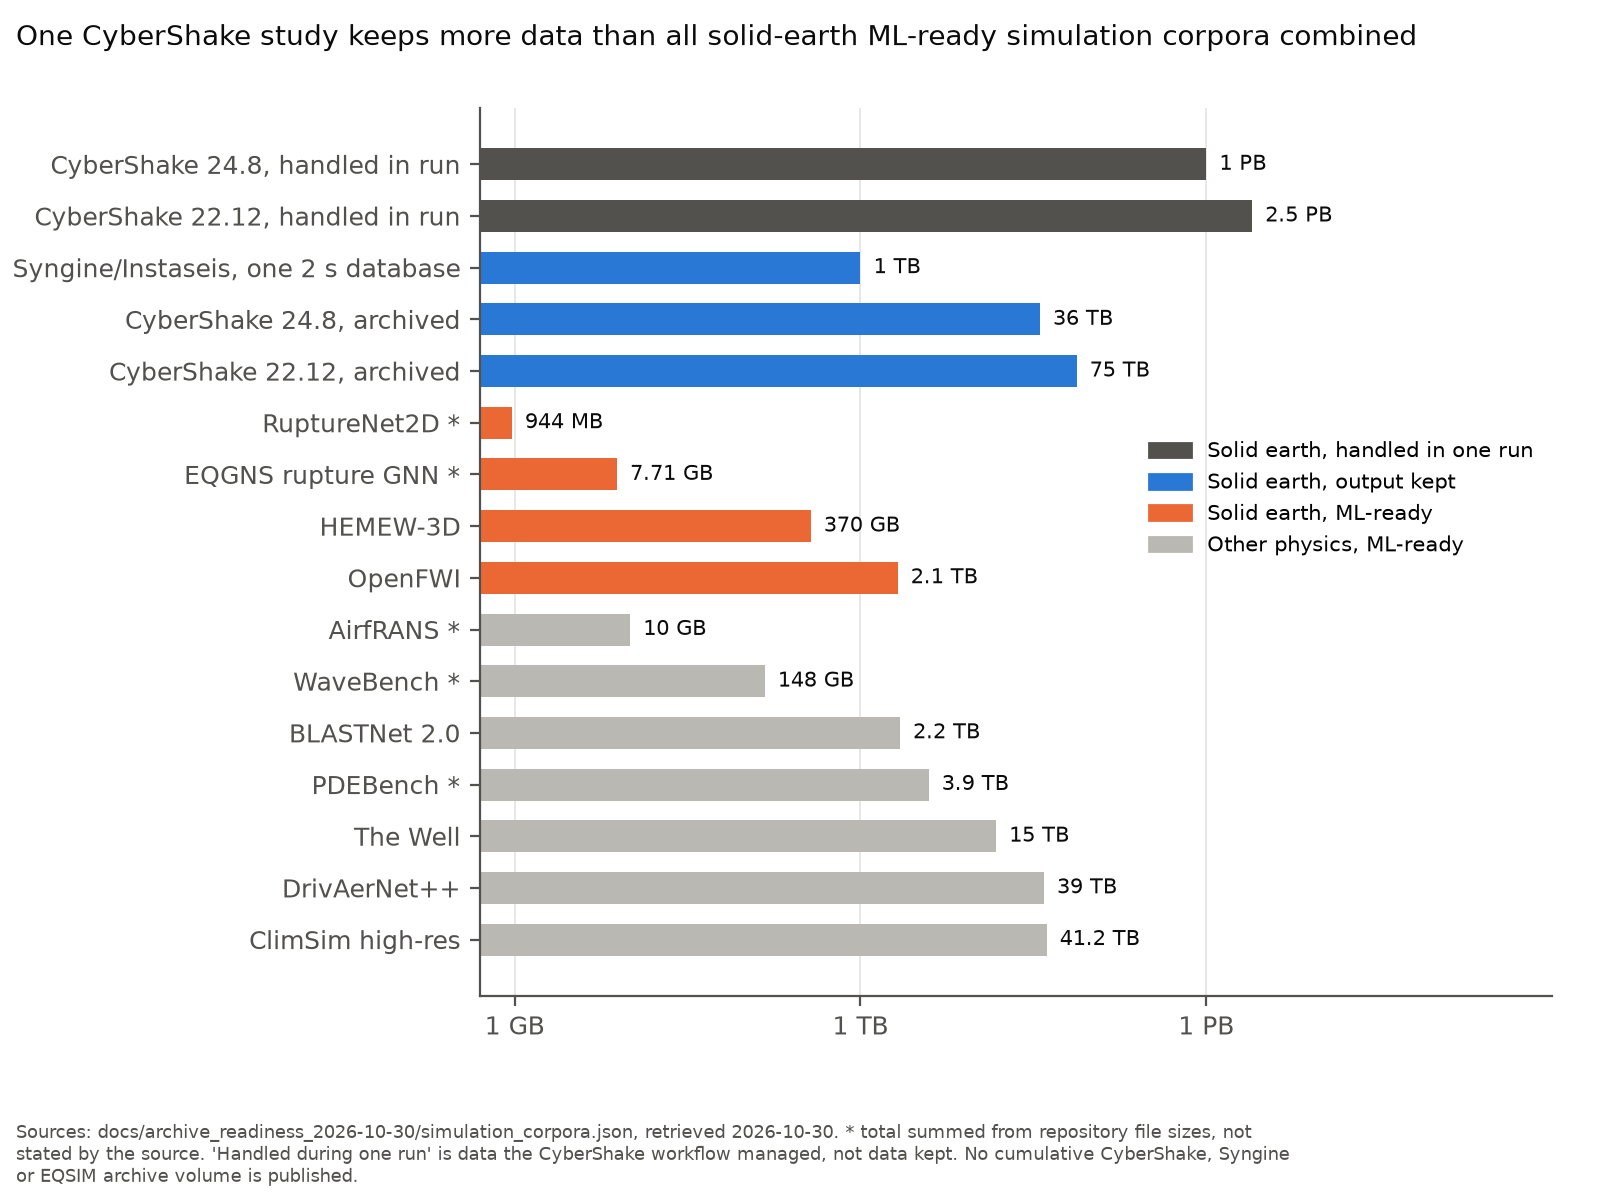

In [6]:
subprocess.run([sys.executable, str(ROOT / "scripts/archive_readiness_figures.py")], check=True, cwd=ROOT, capture_output=True)
for name in ("fig1_archive_vs_ml_ready", "fig5_surrogate_index_by_field", "fig6_surrogate_earth_subfields", "fig7_simulation_corpora"):
    display(Image(filename=str(ROOT / "build/archive_readiness" / f"{name}.png"), width=780))

## 5. Limits

- Archive volumes use different definitions (replicas, online versus tape) and dates from 2020 to 2026; weak figures are flagged in `archives.json`.
- No cumulative volume is published for CyberShake, Syngine, EQSIM, DAS experiments or USGS NWIS.
- Simulation and surrogate counts are keyword co-occurrence in titles and abstracts; surrogate papers need not name a numerical method, so the index is a ratio of two keyword populations.
- Volumes summed from repository file sizes (marked `computed`) are not stated by their sources.